# CNW-Grass gas exchange, 4: sensitivity analysis

**What you will learn:** rank the parameters by their effect on the stand's photosynthesis and transpiration, first
one at a time, then all together by random sampling.

**You need:** tutorials 2 and 3. **Run time:** about a minute.

A **sensitivity analysis** answers: *which parameters matter most for this output?* It tells which parameters need
an accurate measurement, and which can stay at their defaults. The outputs here are the stand's net assimilation and
transpiration at noon:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.cnwgrass.metafspm.simulation import parameters, simulate
from openalea.metafspm.scene.scenarios import variants


def noon(values):
    row = simulate(values, hours=1, start_hour=12).summary.iloc[0]
    return row["net_assimilation"], row["transpiration"]


reference = noon({})
print(f"with the defaults: net assimilation {reference[0]:.3f} µmol m-2 s-1, transpiration {reference[1]:.3f} "
      "mmol m-2 s-1")

with the defaults: net assimilation 10.033 µmol m-2 s-1, transpiration 2.003 mmol m-2 s-1


## 1. One at a time

Each parameter is changed by −10 % and +10 % around its default, the others kept at theirs, and the relative change of
each output is recorded. `variants(..., design="one_at_a_time")` (from metafspm) writes these changes.

,net assimilation,transpiration
Vc_max25_nitrogen_slope,0.0000,0.0000
stomatal_slope,0.0000,0.0000
stem_efficiency,0.0000,0.0000
wind_attenuation,-0.0010,-0.0000
minimum_stomatal_conductance,0.0041,0.0068
BWB_slope_factor,0.0319,0.0290
THETA,0.0796,0.0094
Jmax25_nitrogen_slope,0.0971,0.0117


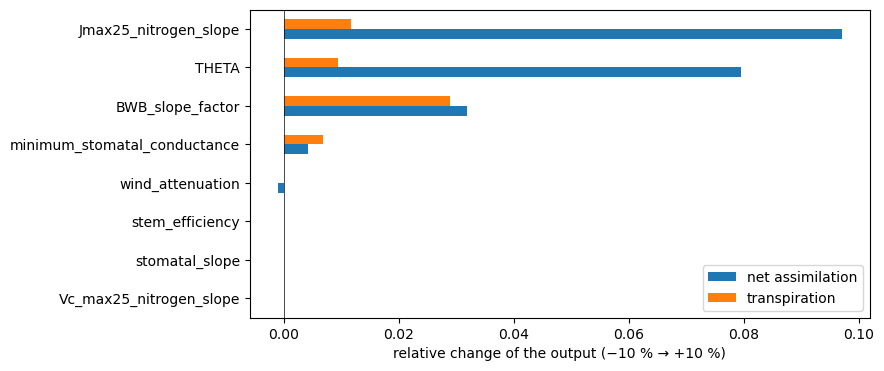

In [2]:
studied = ["Vc_max25_nitrogen_slope", "Jmax25_nitrogen_slope", "THETA", "BWB_slope_factor",
           "minimum_stomatal_conductance", "stomatal_slope", "stem_efficiency", "wind_attenuation"]
defaults = parameters().set_index("name")["value"]
changes = variants({}, {name: [0.9 * defaults[name], 1.1 * defaults[name]] for name in studied},
                   design="one_at_a_time")
outputs = {label: noon(values) for label, values in changes.items() if label != "base"}
effects = {}
for name in studied:
    low, high = (outputs[label] for label in outputs if label.startswith(f"{name}="))
    effects[name] = {"net assimilation": (high[0] - low[0]) / reference[0],
                     "transpiration": (high[1] - low[1]) / reference[1]}
effects = pd.DataFrame(effects).T.sort_values("net assimilation", key=abs)
effects.plot.barh(figsize=(8, 4)); plt.axvline(0, color="k", lw=0.5)
plt.xlabel("relative change of the output (−10 % → +10 %)")
effects.round(4)

**Reading the bars.** A bar of 0.1 means the output changes by 10 % when the parameter goes from −10 % to +10 %.

- The electron transport capacity (`Jmax25_nitrogen_slope`) and the light response's curvature (`THETA`) drive the
  assimilation; the transpiration hardly moves with them.
- The stomata's parameters of the default model (`BWB_slope_factor`, `minimum_stomatal_conductance`) change the
  assimilation and the transpiration a little.
- Three parameters have **no effect at all**, each for its own reason. `Vc_max25_nitrogen_slope`: RuBisCO has capacity
  to spare at the default (tutorial 3). `stomatal_slope`: it belongs to the Leuning and Tuzet models, not to the
  default BWB model. `stem_efficiency`: it scales the stems' and sheaths' gross assimilation only, not their net
  assimilation (the original model's choice, kept). A sensitivity analysis answers for a given model and output:
  before concluding that a parameter does not matter, check what the model does with it.
- `wind_attenuation` barely matters in this short canopy.

The model has no random part: the same parameters always give the same result.

## 2. All together: random sampling

Changing one parameter at a time explores only a cross around the defaults. Here four parameters vary together, each
between −20 % and +20 % of its default. A **Latin hypercube** draws 32 combinations that cover each parameter's range
evenly (`variants(..., design="sampling")`, from metafspm). A linear regression on the standardised parameters gives
**standardised regression coefficients** (SRC): the change of the output, in standard deviations, for a change of one
standard deviation of the parameter. When the regression fits well (R² close to 1), the squared SRCs say which share
of the output's variance each parameter explains.

In [3]:
sampled = ["Vc_max25_nitrogen_slope", "Jmax25_nitrogen_slope", "THETA", "BWB_slope_factor"]
samples = variants({}, {name: (0.8 * defaults[name], 1.2 * defaults[name]) for name in sampled}, design="sampling",
                   samples=32, seed=0)
values = pd.DataFrame(list(samples.values()))[sampled]
output = np.array([noon(scenario)[0] for scenario in samples.values()])

standardised = (values - values.mean()) / values.std()
design = np.column_stack([np.ones(len(values)), standardised.values])
y = (output - output.mean()) / output.std()
coefficients, *_ = np.linalg.lstsq(design, y, rcond=None)
r2 = 1 - np.sum((y - design @ coefficients) ** 2) / np.sum((y - y.mean()) ** 2)
print(pd.Series(coefficients[1:], index=sampled).round(2).to_string())
print(f"R2 = {r2:.3f}")

Vc_max25_nitrogen_slope   -0.01
Jmax25_nitrogen_slope      0.75
THETA                      0.62
BWB_slope_factor           0.25
R2 = 0.994


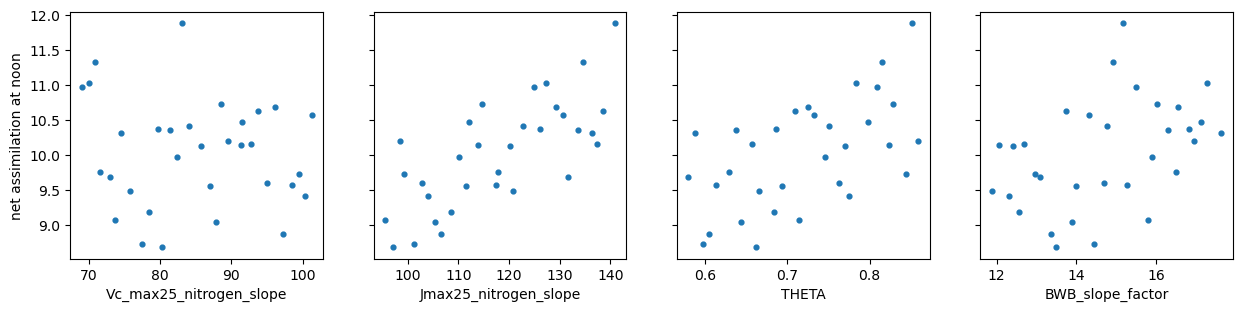

In [4]:
fig, axes = plt.subplots(1, len(sampled), figsize=(15, 3.2), sharey=True)
for ax, name in zip(axes, sampled):
    ax.scatter(values[name], output, s=12); ax.set_xlabel(name)
axes[0].set_ylabel("net assimilation at noon");

**Reading the result.** The SRCs rank the parameters as the one-at-a-time analysis did; the scatter plots show a clear
trend for the influential ones and a cloud for the others. Dedicated libraries (for example SALib) offer more methods
(Morris, Sobol); the principle is the same.

## Try it yourself

1. Repeat the one-at-a-time analysis with the Leuning model (`{"stomatal_model": "Leuning", ...}`): does
   `stomatal_slope` matter now?
2. Repeat it at 8 h (`start_hour=8`), in less light: does the ranking change?
3. Add `surfacic_nitrogen` to the analysis (a `simulate` argument, not a parameter).

**Next:** `05_measured_weather.ipynb`.